## 1. Import Libraries

In [1]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Load Dataset

In [2]:
dataset = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/data_kunjungan_wisata.xlsx')
print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)
print('Lima data teratas:')
print(dataset.head())

Ukuran dataset: 100 baris dan 10 kolom

Lima data teratas:
  id_kunjungan    tanggal           destinasi         kota      jenis_wisata  \
0        KJ001 2025-01-03        Jatim Park 2         Batu    Taman Rekreasi   
1        KJ002 2025-01-04  Pantai Balekambang       Malang            Pantai   
2        KJ003 2025-01-08    Goa Selomangleng       Kediri  Budaya & Sejarah   
3        KJ004 2025-01-15        Gunung Bromo  Probolinggo            Gunung   
4        KJ005 2025-01-17     Batu Secret Zoo         Batu    Taman Rekreasi   

   jumlah_pengunjung  harga_tiket  lama_kunjungan_jam  rating    cuaca  
0                440       150000                 1.6     4.4  Berawan  
1                350        20000                 1.6     3.4  Berawan  
2                 60        10000                 3.1     4.1    Hujan  
3                290        35000                 4.8     4.1  Berawan  
4                440       130000                 3.0     4.5    Cerah  


## 3. Menambahkan kolom bulan_kunjungan pada dataset

In [3]:
dataset['tanggal'] = pd.to_datetime(dataset['tanggal'])
dataset['bulan_kunjungan'] = dataset['tanggal'].apply(lambda x: x.strftime('%Y-%m'))
print(dataset.head())

  id_kunjungan    tanggal           destinasi         kota      jenis_wisata  \
0        KJ001 2025-01-03        Jatim Park 2         Batu    Taman Rekreasi   
1        KJ002 2025-01-04  Pantai Balekambang       Malang            Pantai   
2        KJ003 2025-01-08    Goa Selomangleng       Kediri  Budaya & Sejarah   
3        KJ004 2025-01-15        Gunung Bromo  Probolinggo            Gunung   
4        KJ005 2025-01-17     Batu Secret Zoo         Batu    Taman Rekreasi   

   jumlah_pengunjung  harga_tiket  lama_kunjungan_jam  rating    cuaca  \
0                440       150000                 1.6     4.4  Berawan   
1                350        20000                 1.6     3.4  Berawan   
2                 60        10000                 3.1     4.1    Hujan   
3                290        35000                 4.8     4.1  Berawan   
4                440       130000                 3.0     4.5    Cerah   

  bulan_kunjungan  
0         2025-01  
1         2025-01  
2         2025

### 4. Menambahkan kolom gmv pada dataset

In [4]:
dataset['gmv'] = dataset['harga_tiket'] * dataset['jumlah_pengunjung']
print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)
print('Lima data teratas:')
print(dataset.head())

Ukuran dataset: 100 baris dan 12 kolom

Lima data teratas:
  id_kunjungan    tanggal           destinasi         kota      jenis_wisata  \
0        KJ001 2025-01-03        Jatim Park 2         Batu    Taman Rekreasi   
1        KJ002 2025-01-04  Pantai Balekambang       Malang            Pantai   
2        KJ003 2025-01-08    Goa Selomangleng       Kediri  Budaya & Sejarah   
3        KJ004 2025-01-15        Gunung Bromo  Probolinggo            Gunung   
4        KJ005 2025-01-17     Batu Secret Zoo         Batu    Taman Rekreasi   

   jumlah_pengunjung  harga_tiket  lama_kunjungan_jam  rating    cuaca  \
0                440       150000                 1.6     4.4  Berawan   
1                350        20000                 1.6     3.4  Berawan   
2                 60        10000                 3.1     4.1    Hujan   
3                290        35000                 4.8     4.1  Berawan   
4                440       130000                 3.0     4.5    Cerah   

  bulan_kunjung

## 5. Menambahkan data agregat

In [5]:
gmv_bulanan = dataset.groupby('bulan_kunjungan')['gmv'].sum().reset_index()
print(gmv_bulanan)

   bulan_kunjungan        gmv
0          2025-01  172550000
1          2025-02  285600000
2          2025-03  285330000
3          2025-04  308640000
4          2025-05  304350000
5          2025-06  378800000
6          2025-07  356300000
7          2025-08  306930000
8          2025-09  162490000
9          2025-10  240000000
10         2025-11  159705000
11         2025-12  461450000


### 6. Membuat Line Chart Trend Pertumbuhan GMV

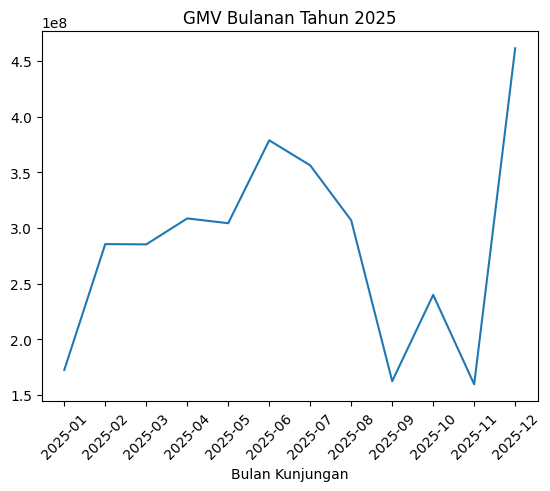

In [6]:
import matplotlib.pyplot as plt
plt.plot(gmv_bulanan['bulan_kunjungan'], gmv_bulanan['gmv'])
plt.title('GMV Bulanan Tahun 2025')
plt.xlabel('Bulan Kunjungan')
plt.xticks(rotation=45)
plt.show()

## 7. Mengubah Figure Size

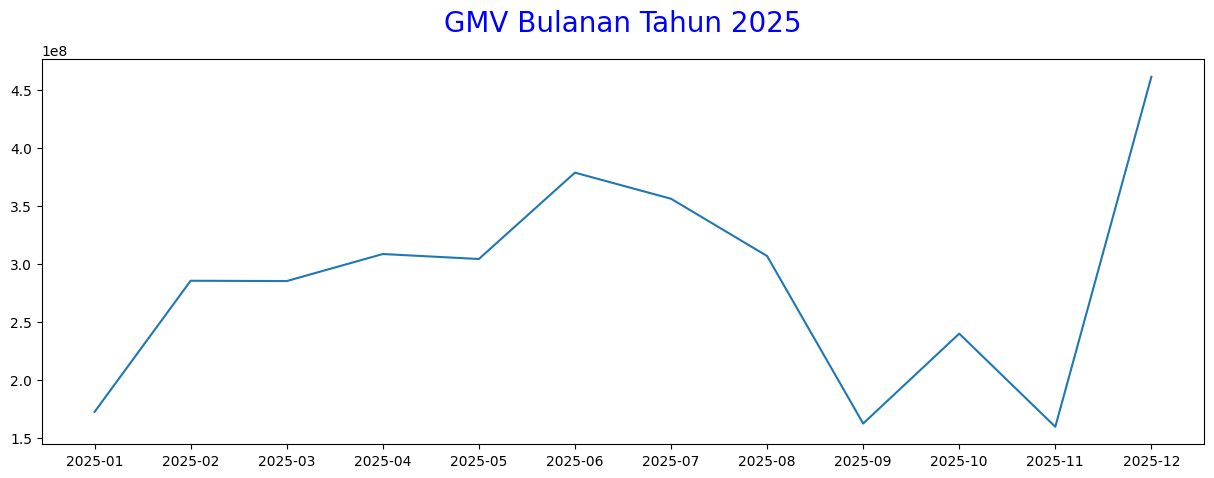

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
plt.plot(gmv_bulanan['bulan_kunjungan'], gmv_bulanan['gmv'])
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.show()

## 8. Menambahkan Title dan Axis Labels

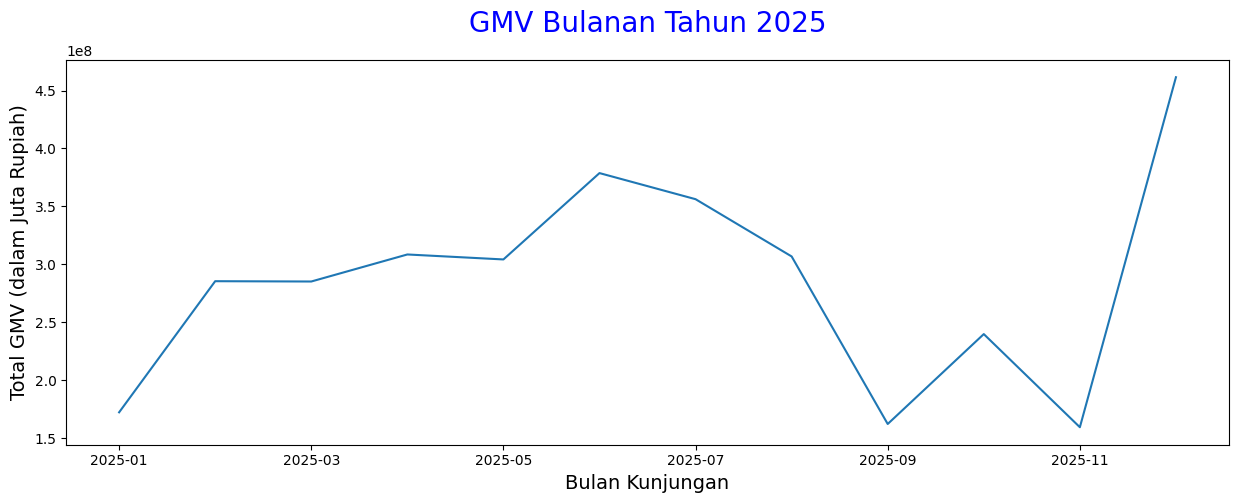

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot()
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=14)
plt.ylabel('Total GMV (Rupiah)', fontsize=14)
plt.show()

## 9. Modifikasi Line dan Point

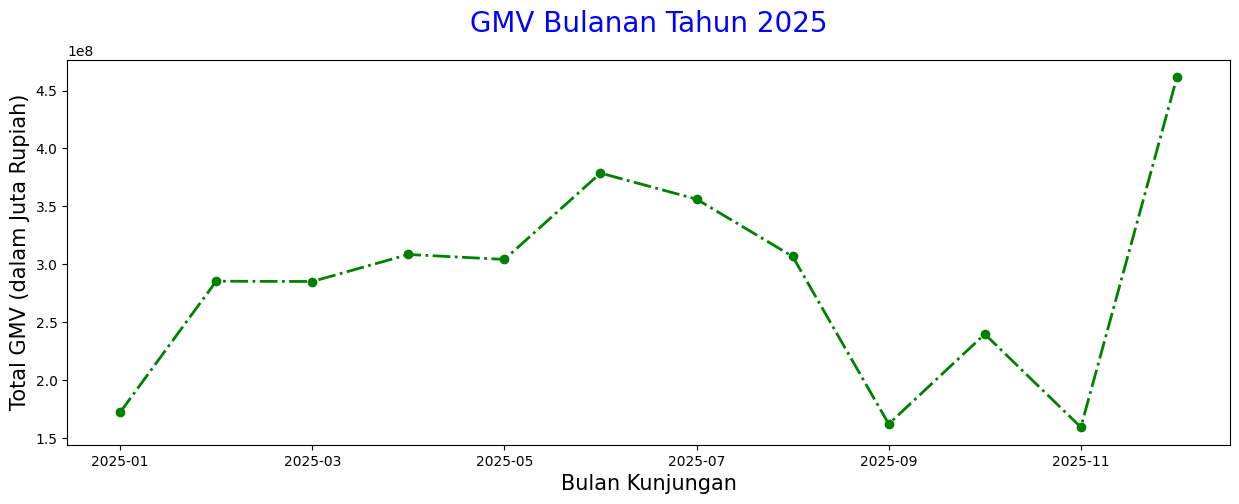

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot(color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (Rupiah)', fontsize=15)
plt.show()

## 10. Modifikasi Grid

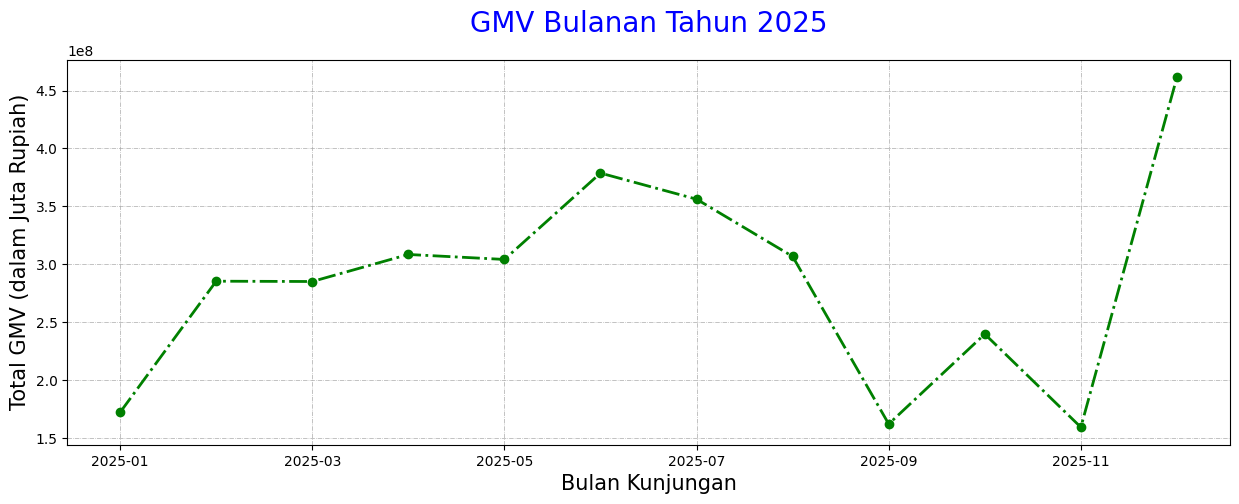

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot(color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (Rupiah)', fontsize=15)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.show()

## 11. Menambahkan Informasi pada Plot

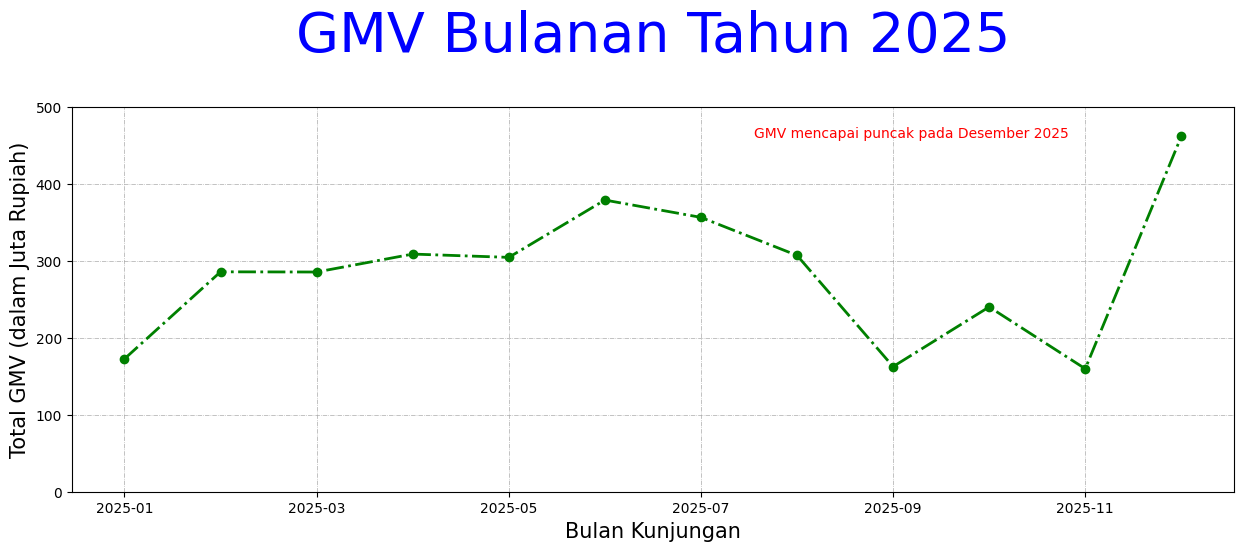

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot(color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=40, fontsize=40, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (dalam Juta Rupiah)', fontsize=15)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.ylim(ymin=0)
labels, location = plt.yticks()
plt.yticks(labels, (labels/1000000).astype(int))
plt.text(0.58, 0.82, "GMV mencapai puncak pada Desember 2025", transform=plt.gcf().transFigure, color='red')
plt.show()